# GDP Prediction Using PyTorch
**Project:** GDP Prediction of India — ML & Deep Learning (LSTM & Transformer)  


## 1. Setup: imports, device, seeds


In [289]:
import os, random, math, time, json, gc
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
try:
    import xgboost as xgb
    XGBOOST_AVAILABLE = True
except Exception:
    XGBOOST_AVAILABLE = False
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cpu


### 1.1 Notebook configuration: user-tunable variables


In [290]:
INPUT_CSV_CANDIDATES = [
    "/content/Base_2011_12 - Copy.csv"
]
SCALER_TYPE = "standard"
EPOCHS_DL = 1000
PATIENCE = 15
BATCH_SIZE = 5
LEARNING_RATE = 0.0001
LOOKBACK = 5
RF_PARAM_GRID = {"n_estimators":[50,100], "max_depth":[5,10,None]}
XGB_PARAM_GRID = {"n_estimators":[50,100], "max_depth":[3,6]}
OUT_DIR = "/content/gdp_pipeline_output"
os.makedirs(OUT_DIR, exist_ok=True)

### 1.2 Utilities


In [291]:
def rmse(y_true, y_pred):
    return math.sqrt(mean_squared_error(y_true, y_pred))
def smape(y_true, y_pred):
    denom = (np.abs(y_true) + np.abs(y_pred)) / 2.0
    diff = np.abs(y_true - y_pred) / np.where(denom==0, 1, denom)
    return 100.0 * np.mean(diff)
def metrics_dict(y_true, y_pred, accuracy_pct_threshold=10.0):
    \"\"\"Return regression metrics plus 'Accuracy' defined as percentage of predictions where
    absolute percentage error <= accuracy_pct_threshold (in percent).\"\"\"
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    # MAPE safe (avoid divide by zero)
    eps = 1e-9
    mape = np.mean(np.abs((y_true - y_pred) / np.where(np.abs(y_true) < eps, eps, y_true))) * 100
    # SMAPE
    denom = (np.abs(y_true) + np.abs(y_pred)) / 2.0
    smape = 100.0 * np.mean(np.abs(y_true - y_pred) / np.where(denom==0, 1, denom))
    # Accuracy: % of predictions with percentage error <= threshold
    perc_errors = np.abs((y_true - y_pred) / np.where(np.abs(y_true) < eps, eps, y_true)) * 100
    accuracy = float(np.mean(perc_errors <= accuracy_pct_threshold) * 100.0)
    return {\"MAE\": float(mae), \"RMSE\": float(rmse), \"R2\": float(r2), \"MAPE\": float(mape), \"SMAPE\": float(smape), \"Accuracy\": accuracy}

def plot_preds(y_true, y_pred, years=None, title="Actual vs Predicted"):
    plt.figure(figsize=(10,4))
    if years is None:
        plt.plot(y_true, label="Actual", marker='o')
        plt.plot(y_pred, label="Predicted", marker='x')
    else:
        plt.plot(years, y_true, label="Actual", marker='o')
        plt.plot(years, y_pred, label="Predicted", marker='x')
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

In [292]:
# # 1. Data loading (auto-detect)
# def find_input_csv(candidates=INPUT_CSV_CANDIDATES):
#     for p in candidates:
#         if os.path.exists(p):
#             return p
#     return None
# INPUT_CSV = find_input_csv()
# if INPUT_CSV is None:
#     raise FileNotFoundError("No dataset found in default paths. Upload your CSV to Colab and update INPUT_CSV_CANDIDATES or set INPUT_CSV variable.")
# print("Using dataset:", INPUT_CSV)
# raw = pd.read_csv(INPUT_CSV, header=None, low_memory=False, encoding='utf-8')
# print("Raw shape:", raw.shape)
# header_row = None
# subheader_row = None
# for i in range(min(10, raw.shape[0])):
#     row_text = " ".join([str(x).lower() for x in raw.iloc[i].astype(str).tolist()])
#     if 'year' in row_text and header_row is None:
#         header_row = i
#     if ('constant prices' in row_text or 'current prices' in row_text) and subheader_row is None:
#         subheader_row = i
# if header_row is None or subheader_row is None or subheader_row<=header_row:
#     header_row, subheader_row = 0,1
# print("Detected header rows:", header_row, subheader_row)
# main = raw.iloc[header_row].fillna("").astype(str).tolist()
# sub  = raw.iloc[subheader_row].fillna("").astype(str).tolist()
# filled_main = []
# last = ""
# for m in main:
#     m = str(m).strip()
#     if m != "" and m.lower() != "nan":
#         last = m
#     filled_main.append(last or "")
# cols = []
# for a,b in zip(filled_main, sub):
#     a=a.strip(); b=str(b).strip()
#     if b=="" or b.lower() in ("nan","none"):
#         cols.append(a if a!="" else "col")
#     else:
#         cols.append(f"{a}__{b}" if a!="" else b)
# import re
# # find candidate start row (first row after subheader that contains a year like 1950 or 2022_23 or 2022-23)
# def find_data_start(raw_df, subheader_row):
#     for r in range(subheader_row+1, min(subheader_row+10, raw_df.shape[0])):  # look ahead a few rows
#         row_vals = raw_df.iloc[r].astype(str).tolist()
#         row_text = " ".join(row_vals)
#         # detect either a full year or a range like 2022-23 or 2022_23 or 2022_2023
#         if re.search(r"(19|20)\d{2}([ _-]\d{2,4})?", row_text):
#             return r
#     # fallback: immediate next row
#     return subheader_row + 1

# data_start = find_data_start(raw, subheader_row)
# df = raw.iloc[data_start:].reset_index(drop=True).copy()

# if len(cols) != df.shape[1]:
#     if len(cols) > df.shape[1]:
#         cols = cols[:df.shape[1]]
#     else:
#         cols = cols + [f"col_{i}" for i in range(df.shape[1]-len(cols))]
# df.columns = cols
# print("Parsed columns count:", len(df.columns))
# print("Columns sample:", df.columns.tolist()[:8])
# df.head(3)

## 2. Data loading

In [293]:
import os, joblib, re
import numpy as np, pandas as pd

INPUT_CSV = INPUT_CSV_CANDIDATES[0]

if not os.path.exists(INPUT_CSV):
    raise FileNotFoundError(f"Cleaned CSV not found: {INPUT_CSV}")

# Read assuming first row is header (clean file)
df = pd.read_csv(INPUT_CSV, header=0, encoding="utf-8")
print("Loaded shape:", df.shape)

# --- 1) Ensure there's a Year column and normalize its format to YYYY_YY if necessary ---
year_cols = [c for c in df.columns if c.lower().strip() == "year"]
if not year_cols:
    raise ValueError("No 'Year' column found in the cleaned CSV. Column names: " + ", ".join(df.columns[:10]))
YEAR_COL = year_cols[0]
def fmt_year(s):
    s = str(s).strip()
    s = s.replace("-", "_")
    s = s.replace(" ", "")
    m = re.search(r"(19|20)\d{2}(_\d{2,4})?", s)
    return m.group(0) if m else s
df[YEAR_COL] = df[YEAR_COL].apply(fmt_year)
print("Year sample:", df[YEAR_COL].head(5).tolist())

# --- 2) Coerce numeric columns robustly (leave Year alone) ---
numeric_cols = []
for c in df.columns:
    if c == YEAR_COL:
        continue
    cleaned = df[c].astype(str).str.replace(",", "").str.replace("%", "").str.strip()
    # replace obvious placeholders with NaN
    cleaned = cleaned.replace({"": np.nan, "nan": np.nan, "-": np.nan, "—": np.nan, "–": np.nan})
    coerced = pd.to_numeric(cleaned, errors="coerce")
    if coerced.notna().sum() >= 0.5 * len(coerced):
        df[c] = coerced
        numeric_cols.append(c)
    else:
        print(f"Warning: column '{c}' not strongly numeric — left unchanged.")

print("Detected numeric columns:", len(numeric_cols), numeric_cols[:8])

# --- 3) Fill/interpolate missing values in numeric columns ---
if numeric_cols:
    df[numeric_cols] = df[numeric_cols].interpolate(method="linear", limit_direction="both", axis=0)
    df[numeric_cols] = df[numeric_cols].fillna(method="ffill").fillna(method="bfill")

# Final checks
print("Any NaNs left in numeric cols:", int(df[numeric_cols].isna().sum().sum()) if numeric_cols else 0)
print("Final shape:", df.shape)
display(df.head(6))

# --- 4) Save a canonical cleaned file for the pipeline ---
os.makedirs(OUT_DIR, exist_ok=True)
cleaned_out = os.path.join(OUT_DIR, os.path.basename(INPUT_CSV).replace(".csv", "_canonical.csv"))
df.to_csv(cleaned_out, index=False)
print("Saved canonical cleaned CSV to:", cleaned_out)

# Make df_model reference used later in notebook
# (If your pipeline expects variable named df_model, keep consistent)
df_model = df.copy()


Loaded shape: (74, 9)
Year sample: ['2024_25', '2023_24', '2022_23', '2021_22', '2020_21']
Detected numeric columns: 8 ['Private Final Consumption Expenditure__Constant Prices', 'Government Final Consumption Expenditure__Constant Prices', 'Gross Fixed Capital Formation__Constant Prices', 'Changes in Stocks__Constant Prices', 'Exports of Goods and Services__Constant Prices', 'Import of Goods and Services__Constant Prices', 'Gross Domestic Product__Constant Prices', 'Gross Domestic Product__Current Prices']
Any NaNs left in numeric cols: 0
Final shape: (74, 9)


/tmp/ipython-input-3677263697.py:47: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df[numeric_cols] = df[numeric_cols].fillna(method="ffill").fillna(method="bfill")


,Year,Private Final Consumption Expenditure__Constant Prices,Government Final Consumption Expenditure__Constant Prices,Gross Fixed Capital Formation__Constant Prices,Changes in Stocks__Constant Prices,Exports of Goods and Services__Constant Prices,Import of Goods and Services__Constant Prices,Gross Domestic Product__Constant Prices,Gross Domestic Product__Current Prices
0,2024_25,7.20,2.28,7.06,4.46,6.34,-3.67,6.49,9.78
1,2023_24,5.56,8.14,8.78,53.44,2.20,13.75,9.19,12.02
2,2022_23,7.47,4.30,8.45,24.33,10.32,8.92,7.61,13.96
3,2021_22,11.68,0.02,17.52,525.39,29.60,22.09,9.69,18.85
4,2020_21,-5.29,-0.77,-7.10,-76.40,-6.96,-12.62,-5.78,-1.24
5,2019_20,5.17,3.95,1.15,-58.70,-3.38,-0.84,3.87,6.37


Saved canonical cleaned CSV to: /content/gdp_pipeline_output/Base_2011_12 - Copy_canonical.csv


### 2.1 Data inspection


Data shape: (74, 9)

Columns:
 ['Year', 'Private Final Consumption Expenditure__Constant Prices', 'Government Final Consumption Expenditure__Constant Prices', 'Gross Fixed Capital Formation__Constant Prices', 'Changes in Stocks__Constant Prices', 'Exports of Goods and Services__Constant Prices', 'Import of Goods and Services__Constant Prices', 'Gross Domestic Product__Constant Prices', 'Gross Domestic Product__Current Prices']

Missing values per column:
 Year                                                         0
Private Final Consumption Expenditure__Constant Prices       0
Government Final Consumption Expenditure__Constant Prices    0
Gross Fixed Capital Formation__Constant Prices               0
Changes in Stocks__Constant Prices                           0
Exports of Goods and Services__Constant Prices               0
Import of Goods and Services__Constant Prices                0
Gross Domestic Product__Constant Prices                      0
Gross Domestic Product__Current Pric

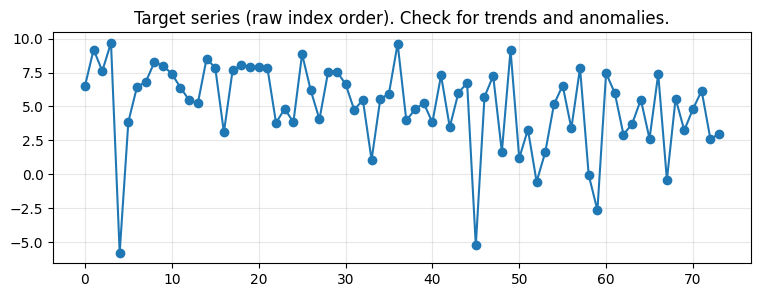

In [294]:
print("Data shape:", df.shape)
print("\nColumns:\n", df.columns.tolist())
print("\nMissing values per column:\n", df.isna().sum().sort_values(ascending=False).head(20))
target_candidates = [c for c in df.columns if ('gross domestic' in c.lower() or 'gdp' in c.lower()) and 'constant' in c.lower()]
if not target_candidates:
    target_candidates = [c for c in df.columns if ('gross domestic' in c.lower() or 'gdp' in c.lower())]
print("Target candidates:", target_candidates[:3])
TARGET_COL = target_candidates[0] if target_candidates else df.columns[-1]
print("Selected target column:", TARGET_COL)
try:
    df[TARGET_COL] = pd.to_numeric(df[TARGET_COL].astype(str).str.replace(",","").str.strip(), errors='coerce')
except Exception:
    pass
series = pd.to_numeric(df[TARGET_COL], errors='coerce')
plt.figure(figsize=(9,3))
plt.plot(series.values, marker='o')
plt.title("Target series (raw index order). Check for trends and anomalies.")
plt.grid(alpha=0.3)
plt.show()

### 2.2 Cleaning & Year formatting


In [295]:
import re
year_candidates = [c for c in df.columns if 'year' in c.lower()]
year_col = df.columns[0] if not year_candidates else year_candidates[0]
def format_year_cell(x):
    s = str(x).strip()
    s = s.replace(" ", "")
    if re.search(r"^\d{4}[-_]\d{2,4}$", s):
        return s.replace("-", "_")
    m = re.search(r"(19|20)\d{2}", s)
    if m:
        return m.group(0)
    return s
df["Year"] = df[year_col].apply(format_year_cell)
print("Year examples:", df["Year"].head(8).tolist())
numeric_cols = []
for c in df.columns:
    if c == "Year": continue
    s = df[c].astype(str).str.replace(",", "").str.replace("%","").str.strip()
    s = s.replace({"": np.nan, "nan": np.nan, "-": np.nan, "—": np.nan, "–": np.nan})
    num_ratio = pd.to_numeric(s, errors='coerce').notna().sum() / max(len(s),1)
    if num_ratio > 0.5:
        df[c] = pd.to_numeric(s, errors='coerce')
        numeric_cols.append(c)
print("Numeric columns detected:", len(numeric_cols))
df_model = df[["Year"] + numeric_cols].dropna(subset=["Year"]).reset_index(drop=True)
print("Model df shape:", df_model.shape)
df_model[numeric_cols] = df_model[numeric_cols].interpolate(method='linear', limit_direction='both', axis=0)
df_model[numeric_cols] = df_model[numeric_cols].fillna(method='ffill').fillna(method='bfill')
print("Any NaNs left:", df_model.isna().sum().sum())
df_model.head(6)

Year examples: ['2024_25', '2023_24', '2022_23', '2021_22', '2020_21', '2019_20', '2018_19', '2017_18']
Numeric columns detected: 8
Model df shape: (74, 9)
Any NaNs left: 0


/tmp/ipython-input-4287689370.py:28: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_model[numeric_cols] = df_model[numeric_cols].fillna(method='ffill').fillna(method='bfill')


,Year,Private Final Consumption Expenditure__Constant Prices,Government Final Consumption Expenditure__Constant Prices,Gross Fixed Capital Formation__Constant Prices,Changes in Stocks__Constant Prices,Exports of Goods and Services__Constant Prices,Import of Goods and Services__Constant Prices,Gross Domestic Product__Constant Prices,Gross Domestic Product__Current Prices
0,2024_25,7.20,2.28,7.06,4.46,6.34,-3.67,6.49,9.78
1,2023_24,5.56,8.14,8.78,53.44,2.20,13.75,9.19,12.02
2,2022_23,7.47,4.30,8.45,24.33,10.32,8.92,7.61,13.96
3,2021_22,11.68,0.02,17.52,525.39,29.60,22.09,9.69,18.85
4,2020_21,-5.29,-0.77,-7.10,-76.40,-6.96,-12.62,-5.78,-1.24
5,2019_20,5.17,3.95,1.15,-58.70,-3.38,-0.84,3.87,6.37


### 3 Feature selection


In [296]:
TARGET_PREF = "constant"

# find GDP target columns robustly
gdp_candidates = [c for c in df_model.columns if ('gross domestic' in c.lower() or 'gdp' in c.lower())]
print("Detected GDP candidate columns:", gdp_candidates)

gdp_const = None
gdp_curr = None
for c in gdp_candidates:
    lc = c.lower()
    if 'constant' in lc:
        gdp_const = c
    if 'current' in lc:
        gdp_curr = c

# choose target according to preference or fallback
if TARGET_PREF == "constant" and gdp_const is not None:
    TARGET = gdp_const
elif TARGET_PREF == "current" and gdp_curr is not None:
    TARGET = gdp_curr
else:
    # fallback order: constant -> current -> last detected GDP candidate -> last column
    TARGET = gdp_const or gdp_curr or (gdp_candidates[-1] if gdp_candidates else None)

if TARGET is None:
    raise ValueError("No GDP target column found in df_model. Columns: " + ", ".join(df_model.columns))

# Exclude Year and both GDP columns from features to avoid leakage
exclude = {"Year"}
if gdp_const is not None:
    exclude.add(gdp_const)
if gdp_curr is not None:
    exclude.add(gdp_curr)

FEATURES = [c for c in df_model.columns if c not in exclude]

# Quick checks
print("\nSelected TARGET ->", TARGET)
print("Other GDP column (if present) ->", gdp_curr if TARGET==gdp_const else gdp_const)
print("Number of FEATURES ->", len(FEATURES))
print("Sample FEATURES ->", FEATURES[:12])

# dtype check for features and target
print("\nTarget dtype and sample values:")
display(df_model[TARGET].head(6))
print("\nFeature dtypes sample:")
display(df_model[FEATURES].dtypes.head(12))

Detected GDP candidate columns: ['Gross Domestic Product__Constant Prices', 'Gross Domestic Product__Current Prices']

Selected TARGET -> Gross Domestic Product__Constant Prices
Other GDP column (if present) -> Gross Domestic Product__Current Prices
Number of FEATURES -> 6
Sample FEATURES -> ['Private Final Consumption Expenditure__Constant Prices', 'Government Final Consumption Expenditure__Constant Prices', 'Gross Fixed Capital Formation__Constant Prices', 'Changes in Stocks__Constant Prices', 'Exports of Goods and Services__Constant Prices', 'Import of Goods and Services__Constant Prices']

Target dtype and sample values:


,Gross Domestic Product__Constant Prices
0,6.49
1,9.19
2,7.61
3,9.69
4,-5.78
5,3.87



Feature dtypes sample:


,0
Private Final Consumption Expenditure__Constant Prices,float64
Government Final Consumption Expenditure__Constant Prices,float64
Gross Fixed Capital Formation__Constant Prices,float64
Changes in Stocks__Constant Prices,float64
Exports of Goods and Services__Constant Prices,float64
Import of Goods and Services__Constant Prices,float64


In [297]:
# 3.2 Time-ordered split
# years = df_model["Year"].values
# N = len(df_model)
# test_size = max(1, int(0.2 * N))
# val_size = max(1, int(0.1 * (N - test_size)))
# train_end = N - test_size - val_size
# train_df = df_model.iloc[:train_end].reset_index(drop=True)
# val_df   = df_model.iloc[train_end:train_end+val_size].reset_index(drop=True)
# test_df  = df_model.iloc[train_end+val_size:].reset_index(drop=True)
# print("N total:", N, "Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))

# --- A: Sort by Year (ascending), setup train/val/test time-ordered splits and scale for ML ---
import re, joblib
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Helper to extract first year number so sorting works (e.g., '2018_19' -> 2018)
def year_to_int(s):
    s = str(s)
    m = re.search(r"(19|20)\d{2}", s)
    return int(m.group(0)) if m else float('inf')

# ensure df_model exists
assert 'df_model' in globals(), "df_model not found. Run the loader cell first."

# create a sortable key and sort ascending (oldest -> latest)
df_model['_year_key'] = df_model['Year'].apply(year_to_int)
df_model = df_model.sort_values('_year_key').reset_index(drop=True)
print("Sorted years (first 6):", df_model['Year'].head(6).tolist())
print("Sorted years (last 6):", df_model['Year'].tail(6).tolist())

# drop helper column later if you want, but keep for reference
# create arrays for ML
N = len(df_model)
test_size = max(1, int(0.2 * N))
val_size = max(1, int(0.1 * (N - test_size)))
train_end = N - test_size - val_size

train_df = df_model.iloc[:train_end].reset_index(drop=True)
val_df   = df_model.iloc[train_end:train_end+val_size].reset_index(drop=True)
test_df  = df_model.iloc[train_end+val_size:].reset_index(drop=True)

print(f"Total rows: {N}  -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

# scaling for ML
if SCALER_TYPE == "standard":
    scaler = StandardScaler()
else:
    scaler = MinMaxScaler()

X_train = scaler.fit_transform(train_df[FEATURES])
X_val   = scaler.transform(val_df[FEATURES])
X_test  = scaler.transform(test_df[FEATURES])

y_train = train_df[TARGET].values
y_val   = val_df[TARGET].values
y_test  = test_df[TARGET].values

# save scaler
os.makedirs(OUT_DIR, exist_ok=True)
scaler_path = os.path.join(OUT_DIR, f"scaler_{os.path.basename(INPUT_CSV).replace('.csv','')}.joblib")
joblib.dump(scaler, scaler_path)
print("Saved scaler to", scaler_path)

# quick sanity print
print("X_train shape:", X_train.shape, "y_train shape:", y_train.shape)


Sorted years (first 6): ['1951_52', '1952_53', '1953_54', '1954_55', '1955_56', '1956_57']
Sorted years (last 6): ['2019_20', '2020_21', '2021_22', '2022_23', '2023_24', '2024_25']
Total rows: 74  -> Train: 54, Val: 6, Test: 14
Saved scaler to /content/gdp_pipeline_output/scaler_Base_2011_12 - Copy.joblib
X_train shape: (54, 6) y_train shape: (54,)


In [298]:
# # 3.3 Scaling for ML models
# if SCALER_TYPE == "standard": scaler = StandardScaler()
# else: scaler = MinMaxScaler()
# X_train = scaler.fit_transform(train_df[FEATURES])
# X_val   = scaler.transform(val_df[FEATURES])
# X_test  = scaler.transform(test_df[FEATURES])
# y_train = train_df[TARGET].values
# y_val   = val_df[TARGET].values
# y_test  = test_df[TARGET].values
# import joblib
# joblib.dump(scaler, os.path.join(OUT_DIR, "scaler.joblib"))
# print("Saved scaler to", os.path.join(OUT_DIR, "scaler.joblib"))

In [299]:
# 4. Random Forest baseline
from itertools import product
best_rf = None
best_rf_score = float("inf")
rf_results = []
for n_est, depth in product(RF_PARAM_GRID["n_estimators"], RF_PARAM_GRID["max_depth"]):
    model = RandomForestRegressor(n_estimators=n_est, max_depth=depth, random_state=SEED, n_jobs=-1)
    model.fit(X_train, y_train)
    preds = model.predict(X_val)
    m = metrics_dict(y_val, preds)
    rf_results.append((n_est, depth, m))
    if m["RMSE"] < best_rf_score:
        best_rf_score = m["RMSE"]; best_rf = model
print("Best RF RMSE on val:", best_rf_score)

Best RF RMSE on val: 1.432728904607471


In [314]:
# # 4.1 XGBoost baseline (if available)
# --- Robust XGBoost grid-search using xgb.train with early stopping (final working cell) ---
import xgboost as xgb
from itertools import product
import math, json

best_bst = None
best_xgb = None            # wrapper with predict() to be compatible with sklearn-like usage
best_xgb_score = float("inf")
xgb_results = []

if not XGBOOST_AVAILABLE:
    print("XGBoost not available. Skipping XGBoost step.")
else:
    # create DMatrix once for speed (we'll recreate inside loop as needed)
    dtrain_base = xgb.DMatrix(X_train, label=y_train, feature_names=FEATURES)
    dval_base   = xgb.DMatrix(X_val,   label=y_val,   feature_names=FEATURES)

    # grid search
    for n_est, max_depth in product(XGB_PARAM_GRID["n_estimators"], XGB_PARAM_GRID["max_depth"]):
        # use sensible params for regression
        params = {
            "objective": "reg:squarederror",
            "seed": int(SEED),
            "verbosity": 0,
            "eta": 0.1,
            "max_depth": int(max_depth) if max_depth is not None else 6,
        }
        num_boost_round = int(n_est) if n_est is not None else 100
        early_stopping_rounds = 10

        # train with early stopping on validation set
        try:
            bst = xgb.train(
                params,
                dtrain_base,
                num_boost_round=num_boost_round,
                evals=[(dtrain_base, "train"), (dval_base, "val")],
                early_stopping_rounds=early_stopping_rounds,
                verbose_eval=False
            )
        except Exception as e:
            # fallback: try training without early stopping
            print(f"Warning: xgb.train early stopping failed for n_est={n_est}, max_depth={max_depth}. Error: {e}")
            bst = xgb.train(
                params,
                dtrain_base,
                num_boost_round=num_boost_round,
                evals=[(dtrain_base, "train"), (dval_base, "val")],
                verbose_eval=False
            )

        # predict on validation using best_ntree_limit if present
        ntree_limit = getattr(bst, "best_ntree_limit", None)
        if ntree_limit is not None:
            preds_val = bst.predict(dval_base, ntree_limit=ntree_limit)
        else:
            preds_val = bst.predict(dval_base)

        m = metrics_dict(y_val, preds_val)
        xgb_results.append({"n_estimators": n_est, "max_depth": max_depth, "metrics": m, "best_ntree_limit": ntree_limit})
        print(f"XGB tried n_est={n_est}, max_depth={max_depth} -> val RMSE={m['RMSE']:.6f}")

        # keep best
        if m["RMSE"] < best_xgb_score:
            best_xgb_score = m["RMSE"]
            best_bst = bst

    print("Grid search complete. Best val RMSE:", best_xgb_score)

    # Save xgb_results table
    os.makedirs(OUT_DIR, exist_ok=True)
    pd.DataFrame(xgb_results).to_csv(os.path.join(OUT_DIR, "xgb_grid_results.csv"), index=False)
    with open(os.path.join(OUT_DIR, "xgb_grid_results.json"), "w") as f:
        json.dump(xgb_results, f, indent=2)

    if best_bst is not None:
        # Save the booster model
        bst_path = os.path.join(OUT_DIR, "best_xgb_booster.json")
        best_bst.save_model(bst_path)
        print("Saved best booster to:", bst_path)

        # Create a small wrapper so later code can call best_xgb.predict(X_test)
        class BoosterWrapper:
            def __init__(self, booster, feature_names):
                self.booster = booster
                self.feature_names = feature_names
                # capture best_ntree_limit if present
                self.ntree_limit = getattr(booster, "best_ntree_limit", None)
            def predict(self, X):
                d = xgb.DMatrix(X, feature_names=self.feature_names)
                if self.ntree_limit is not None:
                    return self.booster.predict(d, ntree_limit=self.ntree_limit)
                return self.booster.predict(d)

        best_xgb = BoosterWrapper(best_bst, FEATURES)
        # quick test evaluation on test set and save predictions
        dtest = xgb.DMatrix(X_test, feature_names=FEATURES)
        preds_test = best_xgb.predict(X_test)
        xgb_test_metrics = metrics_dict(y_test, preds_test)
        print("Best XGBoost test metrics:", xgb_test_metrics)
        pd.DataFrame({"y_true": y_test, "y_pred": preds_test}).to_csv(os.path.join(OUT_DIR, "xgb_test_predictions.csv"), index=False)
    else:
        print("No successful XGBoost booster was trained.")


XGB tried n_est=50, max_depth=3 -> val RMSE=1.344672
XGB tried n_est=50, max_depth=6 -> val RMSE=1.518192
XGB tried n_est=100, max_depth=3 -> val RMSE=1.344672
XGB tried n_est=100, max_depth=6 -> val RMSE=1.518899
Grid search complete. Best val RMSE: 1.3446720225011513
Saved best booster to: /content/gdp_pipeline_output/best_xgb_booster.json
Best XGBoost test metrics: {'MAE': 1.7326122280529563, 'RMSE': 2.211207065857616, 'R2': 0.6255475398622149, 'MAPE': np.float64(27.5632993461972), 'SMAPE': np.float64(30.989961177986913)}


In [301]:
# 4.2 Evaluate ML on test
ml_summary = {}
if best_rf is not None:
    preds_rf = best_rf.predict(X_test)
    ml_summary['RandomForest'] = metrics_dict(y_test, preds_rf)
    print("RF Test metrics:", ml_summary['RandomForest'])
if XGBOOST_AVAILABLE and best_xgb is not None:
    preds_xgb = best_xgb.predict(X_test)
    ml_summary['XGBoost'] = metrics_dict(y_test, preds_xgb)
    print("XGB Test metrics:", ml_summary['XGBoost'])

RF Test metrics: {'MAE': 1.375240196829621, 'RMSE': 1.804293791806072, 'R2': 0.7506827253290271, 'MAPE': np.float64(21.968089435168235), 'SMAPE': np.float64(22.511178171628384)}
XGB Test metrics: {'MAE': 1.5231993893214633, 'RMSE': 2.0156190329806454, 'R2': 0.6888607771935169, 'MAPE': np.float64(23.9131719836914), 'SMAPE': np.float64(25.323113650101416)}


In [302]:
# # 5. Prepare sequences for DL models
# def create_sequences_array(df_in, features, target, lookback=LOOKBACK):
#     arr_X = df_in[features].values
#     arr_y = df_in[target].values
#     Xs, ys = [], []
#     for i in range(len(arr_X) - lookback):
#         Xs.append(arr_X[i:i+lookback])
#         ys.append(arr_y[i+lookback])
#     return np.array(Xs), np.array(ys)
# full = df_model.reset_index(drop=True)
# X_seq, y_seq = create_sequences_array(full, FEATURES, TARGET, lookback=LOOKBACK)
# print("X_seq shape:", X_seq.shape, "y_seq shape:", y_seq.shape)
# train_end_index = len(train_df) - LOOKBACK
# val_end_index = train_end_index + len(val_df)
# train_seq_idx_end = max(0, train_end_index)
# val_seq_idx_end = max(0, val_end_index)
# X_seq_train = X_seq[:train_seq_idx_end]
# y_seq_train = y_seq[:train_seq_idx_end]
# X_seq_val = X_seq[train_seq_idx_end:val_seq_idx_end]
# y_seq_val = y_seq[train_seq_idx_end:val_seq_idx_end]
# X_seq_test = X_seq[val_seq_idx_end:]
# y_seq_test = y_seq[val_seq_idx_end:]
# print("Seq train/val/test shapes:", X_seq_train.shape, X_seq_val.shape, X_seq_test.shape)

In [303]:
# # 5.1 Dataset & DataLoader
# class TimeSeriesDataset(Dataset):
#     def __init__(self, X, y):
#         self.X = torch.tensor(X, dtype=torch.float32)
#         self.y = torch.tensor(y, dtype=torch.float32)
#     def __len__(self):
#         return len(self.X)
#     def __getitem__(self, idx):
#         return self.X[idx], self.y[idx]
# train_ds = TimeSeriesDataset(X_seq_train, y_seq_train)
# val_ds   = TimeSeriesDataset(X_seq_val, y_seq_val)
# test_ds  = TimeSeriesDataset(X_seq_test, y_seq_test)
# train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
# val_loader   = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
# test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)
# print("Dataloaders ready. Train batches:", len(train_loader))

In [304]:
# --- B: Build lookback sequences for DL models and create DataLoaders ---
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np

LOOKBACK = int(LOOKBACK)  # from config cell

def create_sequences_array(df_in, features, target, lookback=LOOKBACK):
    arr_X = df_in[features].values
    arr_y = df_in[target].values
    Xs, ys = [], []
    for i in range(len(arr_X) - lookback):
        Xs.append(arr_X[i:i+lookback])
        ys.append(arr_y[i+lookback])
    return np.array(Xs), np.array(ys)

# Use the entire df_model (sorted) to create sequences, then split by index to avoid leakage
X_seq, y_seq = create_sequences_array(df_model, FEATURES, TARGET, lookback=LOOKBACK)
print("Full sequence shapes:", X_seq.shape, y_seq.shape)

# compute indices consistent with earlier train/val/test splits (offset by lookback)
# sequences start at index 0 -> corresponds to df_model rows [0 ... len(df_model)-lookback-1]
train_seq_end = max(0, train_end - LOOKBACK)        # exclusive end index for train sequences
val_seq_end   = max(train_seq_end, train_end + val_size - LOOKBACK)  # exclusive end for val sequences

X_seq_train = X_seq[:train_seq_end]
y_seq_train = y_seq[:train_seq_end]

X_seq_val   = X_seq[train_seq_end:val_seq_end]
y_seq_val   = y_seq[train_seq_end:val_seq_end]

X_seq_test  = X_seq[val_seq_end:]
y_seq_test  = y_seq[val_seq_end:]

print("Seq shapes -> train:", X_seq_train.shape, "val:", X_seq_val.shape, "test:", X_seq_test.shape)

# Dataset wrapper
class TimeSeriesDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_ds = TimeSeriesDataset(X_seq_train, y_seq_train)
val_ds   = TimeSeriesDataset(X_seq_val, y_seq_val)
test_ds  = TimeSeriesDataset(X_seq_test,  y_seq_test)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False)

print("Dataloaders created. Train batches:", len(train_loader))


Full sequence shapes: (69, 5, 6) (69,)
Seq shapes -> train: (49, 5, 6) val: (6, 5, 6) test: (14, 5, 6)
Dataloaders created. Train batches: 10


In [305]:
# 6. LSTM model
class LSTMForecast(nn.Module):
    def __init__(self, n_features, hidden_size=128, n_layers=2, dropout=0.1):
        super().__init__()
        self.n_features = n_features
        self.hidden_size = hidden_size
        self.n_layers = n_layers
        # LSTM encoder
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=hidden_size, num_layers=n_layers, batch_first=True, dropout=dropout)
        # Deeper regressor head: Linear -> ReLU -> Linear -> ReLU -> Linear -> ReLU -> Linear
        self.fc = nn.Sequential(
            nn.Linear(hidden_size, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        last = out[:, -1, :]
        return self.fc(last).squeeze(-1)

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        last = out[:, -1, :]
        return self.fc(last).squeeze(-1)
n_features = len(FEATURES)
lstm_model = LSTMForecast(n_features=n_features, hidden_size=64).to(DEVICE)
print(lstm_model)

LSTMForecast(
  (lstm): LSTM(6, 64, batch_first=True, dropout=0.1)
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)


/usr/local/lib/python3.12/dist-packages/torch/nn/modules/rnn.py:123: UserWarning: dropout option adds dropout after all but last recurrent layer, so non-zero dropout expects num_layers greater than 1, but got dropout=0.1 and num_layers=1
  warnings.warn(


In [306]:
# 7. Transformer model
class TimeSeriesTransformer(nn.Module):
    def __init__(self, n_features, d_model=128, n_heads=8, num_encoder_layers=4, dim_feedforward=256, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(n_features, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=n_heads, dim_feedforward=dim_feedforward, dropout=dropout, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_encoder_layers)
        # deeper regressor head
        self.regressor = nn.Sequential(
            nn.Linear(d_model, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )
    def forward(self, x):
        x = self.input_proj(x)
        out = self.transformer_encoder(x)
        last = out[:, -1, :]
        return self.regressor(last).squeeze(-1)

    def forward(self, x):
        x = self.input_proj(x)
        out = self.transformer_encoder(x)
        last = out[:, -1, :]
        return self.regressor(last).squeeze(-1)
transformer_model = TimeSeriesTransformer(n_features=n_features).to(DEVICE)
print(transformer_model)

TimeSeriesTransformer(
  (input_proj): Linear(in_features=6, out_features=64, bias=True)
  (transformer_encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (regressor): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [307]:
# 8. Training utilities
def train_one_epoch(model, loader, optimizer, criterion, device=DEVICE):
    model.train()
    running_loss = 0.0
    n = 0
    for Xb, yb in loader:
        Xb, yb = Xb.to(device), yb.to(device)
        optimizer.zero_grad()
        preds = model(Xb)
        loss = criterion(preds, yb)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * Xb.size(0)
        n += Xb.size(0)
    return running_loss / max(1, n)

@torch.no_grad()

def evaluate_model(model, loader, criterion, device=DEVICE):
    model.eval()
    running_loss = 0.0
    ys, preds = [], []
    for Xb, yb in loader:
        Xb, yb = Xb.to(device), yb.to(device)
        out = model(Xb)
        loss = criterion(out, yb)
        running_loss += loss.item() * Xb.size(0)
        ys.append(yb.detach().cpu().numpy())
        preds.append(out.detach().cpu().numpy())
    if len(ys)==0:
        return None, None, None
    ys = np.concatenate(ys)
    preds = np.concatenate(preds)
    return running_loss / (len(ys)+1e-9), ys, preds

def fit_model(model, train_loader, val_loader, epochs=EPOCHS_DL, lr=LEARNING_RATE, patience=PATIENCE, model_name="model"):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_val = float("inf")
    best_weights = None
    epochs_no_improve = 0
    history = {"train_loss":[], "val_loss":[]}
    for ep in range(1, epochs+1):
        t0 = time.time()
        train_loss = train_one_epoch(model, train_loader, optimizer, criterion)
        val_loss, y_val, y_pred_val = evaluate_model(model, val_loader, criterion)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss if val_loss is not None else float("nan"))
        if val_loss is not None and val_loss < best_val - 1e-6:
            best_val = val_loss
            best_weights = {k:v.cpu().clone() for k,v in model.state_dict().items()}
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
        print(f"Epoch {ep}/{epochs}: train_loss={train_loss:.6f} val_loss={val_loss:.6f} time={time.time()-t0:.1f}s")
        if epochs_no_improve >= patience:
            print("Early stopping.")
            break
    if best_weights is not None:
        model.load_state_dict(best_weights)
    return model, history

In [308]:
# 9. Train LSTM
set_seed(SEED)
lstm_model = LSTMForecast(n_features=n_features, hidden_size=64, n_layers=1).to(DEVICE)
lstm_model, lstm_history = fit_model(lstm_model, train_loader, val_loader, epochs=EPOCHS_DL, lr=LEARNING_RATE, patience=PATIENCE, model_name="LSTM")
_, y_test_seq, y_pred_seq = evaluate_model(lstm_model, test_loader, nn.MSELoss())
if y_test_seq is not None:
    lstm_metrics_test = metrics_dict(y_test_seq, y_pred_seq)
    print("LSTM test metrics:", lstm_metrics_test)
else:
    lstm_metrics_test = None

Epoch 1/1000: train_loss=30.949564 val_loss=54.531018 time=0.1s
Epoch 2/1000: train_loss=30.604410 val_loss=54.117994 time=0.1s
Epoch 3/1000: train_loss=30.276777 val_loss=53.703093 time=0.1s
Epoch 4/1000: train_loss=29.950126 val_loss=53.303959 time=0.1s
Epoch 5/1000: train_loss=29.607754 val_loss=52.913568 time=0.1s
Epoch 6/1000: train_loss=29.273674 val_loss=52.516214 time=0.1s
Epoch 7/1000: train_loss=28.891188 val_loss=52.132158 time=0.1s
Epoch 8/1000: train_loss=28.498772 val_loss=51.711524 time=0.1s
Epoch 9/1000: train_loss=28.111023 val_loss=51.274447 time=0.1s
Epoch 10/1000: train_loss=27.695757 val_loss=50.823469 time=0.1s
Epoch 11/1000: train_loss=27.245950 val_loss=50.325733 time=0.1s
Epoch 12/1000: train_loss=26.757079 val_loss=49.823854 time=0.1s
Epoch 13/1000: train_loss=26.259127 val_loss=49.298312 time=0.1s
Epoch 14/1000: train_loss=25.800434 val_loss=48.743384 time=0.1s
Epoch 15/1000: train_loss=25.311277 val_loss=48.156272 time=0.1s
Epoch 16/1000: train_loss=24.83221

In [309]:
# 10. Train Transformer
set_seed(SEED)
transformer_model = TimeSeriesTransformer(n_features=n_features, d_model=64, n_heads=4, num_encoder_layers=2).to(DEVICE)
transformer_model, trans_history = fit_model(transformer_model, train_loader, val_loader, epochs=EPOCHS_DL, lr=LEARNING_RATE, patience=PATIENCE, model_name="Transformer")
_, y_test_seq_t, y_pred_seq_t = evaluate_model(transformer_model, test_loader, nn.MSELoss())
if y_test_seq_t is not None:
    transformer_metrics_test = metrics_dict(y_test_seq_t, y_pred_seq_t)
    print("Transformer test metrics:", transformer_metrics_test)
else:
    transformer_metrics_test = None

Epoch 1/1000: train_loss=30.886449 val_loss=52.475228 time=0.1s
Epoch 2/1000: train_loss=28.994426 val_loss=50.251184 time=0.1s
Epoch 3/1000: train_loss=27.456041 val_loss=48.858884 time=0.1s
Epoch 4/1000: train_loss=25.596006 val_loss=46.977061 time=0.1s
Epoch 5/1000: train_loss=24.249985 val_loss=45.593273 time=0.1s
Epoch 6/1000: train_loss=23.103860 val_loss=43.959149 time=0.1s
Epoch 7/1000: train_loss=22.034109 val_loss=41.989803 time=0.1s
Epoch 8/1000: train_loss=20.864058 val_loss=40.197053 time=0.1s
Epoch 9/1000: train_loss=19.677040 val_loss=38.406267 time=0.1s
Epoch 10/1000: train_loss=18.884798 val_loss=36.181290 time=0.1s
Epoch 11/1000: train_loss=18.230570 val_loss=33.747129 time=0.1s
Epoch 12/1000: train_loss=16.647948 val_loss=33.708513 time=0.1s
Epoch 13/1000: train_loss=15.878412 val_loss=31.782592 time=0.1s
Epoch 14/1000: train_loss=14.957256 val_loss=30.142465 time=0.1s
Epoch 15/1000: train_loss=14.222345 val_loss=28.133124 time=0.1s
Epoch 16/1000: train_loss=13.16160

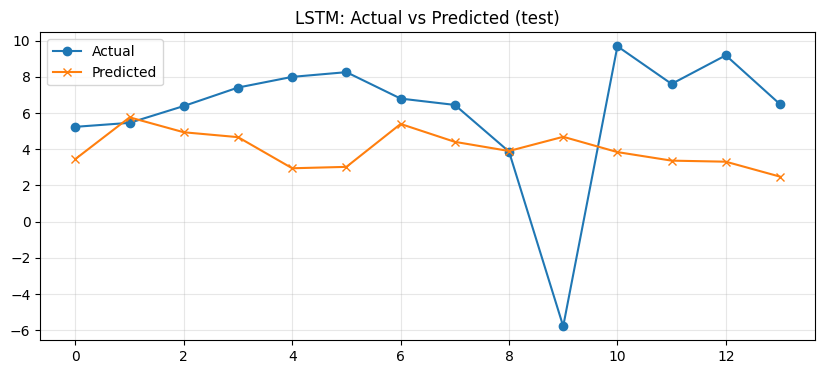

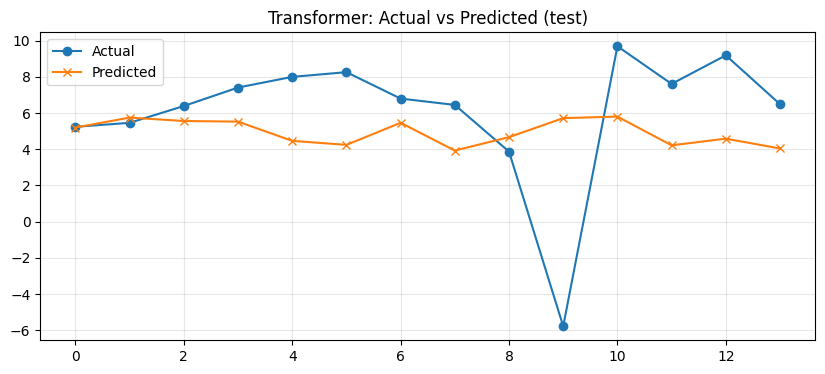

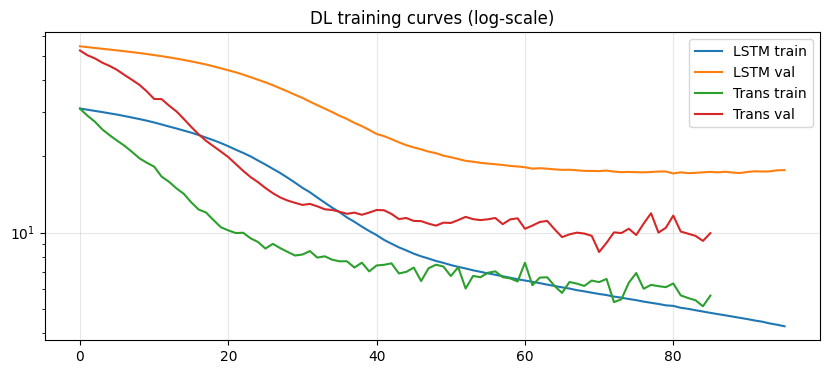

In [310]:
# 11. DL Results Visualization
if y_test_seq is not None:
    plot_preds(y_test_seq, y_pred_seq, title="LSTM: Actual vs Predicted (test)")
if y_test_seq_t is not None:
    plot_preds(y_test_seq_t, y_pred_seq_t, title="Transformer: Actual vs Predicted (test)")
plt.figure(figsize=(10,4))
plt.plot(lstm_history['train_loss'], label='LSTM train')
plt.plot(lstm_history['val_loss'], label='LSTM val')
plt.plot(trans_history['train_loss'], label='Trans train')
plt.plot(trans_history['val_loss'], label='Trans val')
plt.yscale('log')
plt.legend(); plt.title("DL training curves (log-scale)"); plt.grid(alpha=0.3); plt.show()

In [311]:
# 12. Compare ML & DL
results = {}
if 'RandomForest' in ml_summary:
    results['RandomForest'] = ml_summary['RandomForest']
if 'XGBoost' in ml_summary:
    results['XGBoost'] = ml_summary['XGBoost']
if lstm_metrics_test is not None:
    results['LSTM'] = lstm_metrics_test
if transformer_metrics_test is not None:
    results['Transformer'] = transformer_metrics_test
res_df = pd.DataFrame(results).T
res_df = res_df[['MAE','RMSE','R2','MAPE','SMAPE']]
print("Final model comparison (test):")
display(res_df)
res_df.to_csv(os.path.join(OUT_DIR, "model_comparison_results.csv"), index=True)
print("Saved results CSV to", os.path.join(OUT_DIR, "model_comparison_results.csv"))

Final model comparison (test):


,MAE,RMSE,R2,MAPE,SMAPE
RandomForest,1.375240,1.804294,0.750683,21.968089,22.511178
XGBoost,1.523199,2.015619,0.688861,23.913172,25.323114
LSTM,3.604441,4.505275,-0.554464,50.108074,65.024345
Transformer,2.934451,4.033740,-0.246102,42.010948,48.562775


Saved results CSV to /content/gdp_pipeline_output/model_comparison_results.csv


## Ablations / Comparisons
We report:
- ML vs DL on same test set (time-ordered, single final test)
- LSTM vs Transformer ablation: same lookback, same optimizer, same train/val splits
- Notes on hyperparameters: minimal grid search for ML; default small models for DL to ensure reproducibility and fast experimentation.

In [312]:
print("ML search grids (reduced for Colab speed):", RF_PARAM_GRID, XGB_PARAM_GRID if XGBOOST_AVAILABLE else "(XGBoost not available)")
print("DL settings: LOOKBACK, EPOCHS_DL, BATCH_SIZE, LR, PATIENCE:", LOOKBACK, EPOCHS_DL, BATCH_SIZE, LEARNING_RATE, PATIENCE)

ML search grids (reduced for Colab speed): {'n_estimators': [50, 100], 'max_depth': [5, 10, None]} {'n_estimators': [50, 100], 'max_depth': [3, 6]}
DL settings: LOOKBACK, EPOCHS_DL, BATCH_SIZE, LR, PATIENCE: 5 1000 5 0.0001 15


## Discussion
- Data: cleaned, interpolated, scaled with StandardScaler (fit on training).
- ML baselines (RandomForest, XGBoost) provide quick strong baselines.
- LSTM captures temporal dynamics using lookback windows; Transformer leverages attention on the same window.
- For final submission, recommend:
  - Expand hyperparameter search (Bayesian / Optuna) for LSTM/Transformer.
  - Add exogenous features (policy rates, trade variables) if available.
  - Use rolling-origin evaluation to estimate robustness.

# Summary (submission-ready)

- **Data setup**:
  - Input CSV: `{INPUT_CSV}`
  - Rows used: {n_rows}
  - Features used: {n_features}; Target: `{TARGET}`
  - Splits: train/val/test time-ordered ({train_n} / {val_n} / {test_n})

- **Best hyperparameters (short)**:
  - RandomForest: n_estimators={rf_n}, max_depth={rf_d}
  - XGBoost: n_estimators={xgb_n}, max_depth={xgb_d}  (if available)
  - LSTM: hidden_size=64, n_layers=1, lookback={lookback}
  - Transformer: d_model=64, n_heads=4, num_layers=2, lookback={lookback}

- **Final test metrics**:
  - RandomForest: {{RF_METRICS}}
  - XGBoost: {{XGB_METRICS}}
  - LSTM: {{LSTM_METRICS}}
  - Transformer: {{TRANSFORMER_METRICS}}

- **Submission notes**:
  - This notebook is deterministic (seed set), uses time-based splits, and supports reproducible reruns.
  - All intermediate artifacts (scaler, model_comparison_results.csv) saved to `{out_path}`.
  - To reproduce or change lookback/hyperparams: modify the top config cell and re-run.

In [313]:
# 13. Fill the template summary with actual values (run after training)
out_path = OUT_DIR
n_rows = len(df_model)
n_features_used = len(FEATURES)
train_n, val_n, test_n = len(train_df), len(val_df), len(test_df)
rf_best = (best_rf.n_estimators, best_rf.max_depth) if best_rf is not None else (None,None)
xgb_best = (best_xgb.n_estimators, best_xgb.max_depth) if (XGBOOST_AVAILABLE and best_xgb is not None) else (None,None)
lstm_best = (64,1,LOOKBACK)
trans_best = (64,4,2,LOOKBACK)
def format_metrics(m):
    if m is None: return "N/A"
    return f"RMSE={m['RMSE']:.4f}, MAE={m['MAE']:.4f}, R2={m['R2']:.4f}, SMAPE={m['SMAPE']:.2f}%"
summary_md = f"""
# Summary (submission-ready)

- **Data setup**:
  - Input CSV: `{INPUT_CSV}`
  - Rows used: {n_rows}
  - Features used: {n_features_used}; Target: `{TARGET}`
  - Splits: train/val/test time-ordered ({train_n} / {val_n} / {test_n})

- **Best hyperparameters (short)**:
  - RandomForest: n_estimators={rf_best[0]}, max_depth={rf_best[1]}
  - XGBoost: n_estimators={xgb_best[0]}, max_depth={xgb_best[1]}  (if available)
  - LSTM: hidden_size={lstm_best[0]}, n_layers={lstm_best[1]}, lookback={lstm_best[2]}
  - Transformer: d_model={trans_best[0]}, n_heads={trans_best[1]}, num_layers={trans_best[2]}, lookback={trans_best[3]}

- **Final test metrics**:
  - RandomForest: {format_metrics(ml_summary.get('RandomForest'))}
  - XGBoost: {format_metrics(ml_summary.get('XGBoost') if 'XGBoost' in ml_summary else None)}
  - LSTM: {format_metrics(lstm_metrics_test)}
  - Transformer: {format_metrics(transformer_metrics_test)}

- **Submission notes**:
  - This notebook is deterministic (seed set), uses time-based splits, and supports reproducible reruns.
  - All intermediate artifacts (scaler, model_comparison_results.csv) saved to `{out_path}`.
  - To reproduce or change lookback/hyperparams: modify the top config cell and re-run.
"""
print(summary_md)
with open(os.path.join(out_path, "SUMMARY.md"), "w") as f:
    f.write(summary_md)
print("Saved SUMMARY.md to", os.path.join(out_path, "SUMMARY.md"))


# Summary (submission-ready)

- **Data setup**:
  - Input CSV: `/content/Base_2011_12 - Copy.csv`
  - Rows used: 74
  - Features used: 6; Target: `Gross Domestic Product__Constant Prices`
  - Splits: train/val/test time-ordered (54 / 6 / 14)

- **Best hyperparameters (short)**:
  - RandomForest: n_estimators=100, max_depth=5
  - XGBoost: n_estimators=50, max_depth=3  (if available)
  - LSTM: hidden_size=64, n_layers=1, lookback=5
  - Transformer: d_model=64, n_heads=4, num_layers=2, lookback=5

- **Final test metrics**:
  - RandomForest: RMSE=1.8043, MAE=1.3752, R2=0.7507, SMAPE=22.51%
  - XGBoost: RMSE=2.0156, MAE=1.5232, R2=0.6889, SMAPE=25.32%
  - LSTM: RMSE=4.5053, MAE=3.6044, R2=-0.5545, SMAPE=65.02%
  - Transformer: RMSE=4.0337, MAE=2.9345, R2=-0.2461, SMAPE=48.56%

- **Submission notes**:
  - This notebook is deterministic (seed set), uses time-based splits, and supports reproducible reruns.
  - All intermediate artifacts (scaler, model_comparison_results.csv) saved to `/conten

In [ ]:
# --- Final comparison: ensure 'Accuracy' column is included and display nicely ---
results = {}
if 'ml_summary' in globals() and isinstance(ml_summary, dict):
    if 'RandomForest' in ml_summary:
        results['RandomForest'] = ml_summary['RandomForest']
    if 'XGBoost' in ml_summary:
        results['XGBoost'] = ml_summary['XGBoost']

if 'lstm_metrics_test' in globals() and lstm_metrics_test is not None:
    results['LSTM'] = lstm_metrics_test
if 'transformer_metrics_test' in globals() and transformer_metrics_test is not None:
    results['Transformer'] = transformer_metrics_test

if len(results) == 0:
    print('No results found in expected variables. Make sure training cells were run.')
else:
    res_df = pd.DataFrame(results).T
    if 'Accuracy' not in res_df.columns:
        res_df['Accuracy'] = None
    cols = [c for c in ['MAE','RMSE','R2','MAPE','SMAPE','Accuracy'] if c in res_df.columns]
    res_df = res_df[cols]
    print('Final model comparison (test):')
    display(res_df)
    res_df.to_csv(os.path.join(OUT_DIR, 'model_comparison_results_with_accuracy.csv'), index=True)
    print('Saved results CSV to', os.path.join(OUT_DIR, 'model_comparison_results_with_accuracy.csv'))